<a href="https://colab.research.google.com/github/Borson277/Study_Spot_Finder/blob/main/Study_spot_finder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import glob
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score,
                             classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score)
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

FEATURES = ["Noise", "Lighting", "Crowd", "Temperature", "WiFi", "Seating"]
TARGET = "Productivity"
ZONE_ORDER = ["Optimal", "Moderate", "Poor"]
ZONE_COLORS = {"Optimal": "#2a9d8f", "Moderate": "#e9a23b", "Poor": "#d1495b"}


def section(title):
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


def save_show(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

In [15]:

section("STEP 0 - LOAD AND CLEAN THE DATA")

csv_files = [f for f in glob.glob("*.csv") if "predictions" not in f.lower()]
if not csv_files:
    try:  # running in Google Colab -> ask for the file
        from google.colab import files
        print("Upload the Google Forms CSV file:")
        uploaded = files.upload()
        csv_files = list(uploaded.keys())
    except ImportError:
        raise FileNotFoundError("Put the survey CSV in the same folder as this script.")

CSV_PATH = csv_files[0]
raw = pd.read_csv(CSV_PATH)
print(f"File loaded      : {CSV_PATH}")
print(f"Raw shape        : {raw.shape[0]} rows x {raw.shape[1]} columns")


STEP 0 - LOAD AND CLEAN THE DATA
Upload the Google Forms CSV file:


Saving Study_spot_finder.csv to Study_spot_finder.csv
File loaded      : Study_spot_finder.csv
Raw shape        : 154 rows x 8 columns


Rows removed     : 0 (missing or outside the 1-10 scale)
Clean shape      : 154 rows
Duplicate ratings: 4

First 5 rows:
                   Location  Noise  Lighting  Crowd  Temperature  WiFi  Seating  Productivity
0                   Library      7         5      5            4     1        3             6
1       Library, Class Room      4         5      3            8     1        5             5
2                Class Room      5         8      8            5     2        5             5
3                   Library      1         4      5            2     4        5             5
4  Borall Hall reading room      3         6     10            6     8        5             6

Summary statistics (1-10 scale):
              count  mean   std  min   25%  50%   75%   max
Noise         154.0  4.09  2.62  1.0  2.00  3.0  6.00  10.0
Lighting      154.0  6.18  2.46  1.0  4.25  6.0  8.00  10.0
Crowd         154.0  5.75  2.48  1.0  4.00  5.0  7.75  10.0
Temperature   154.0  5.47  2.74  1.0  4.0

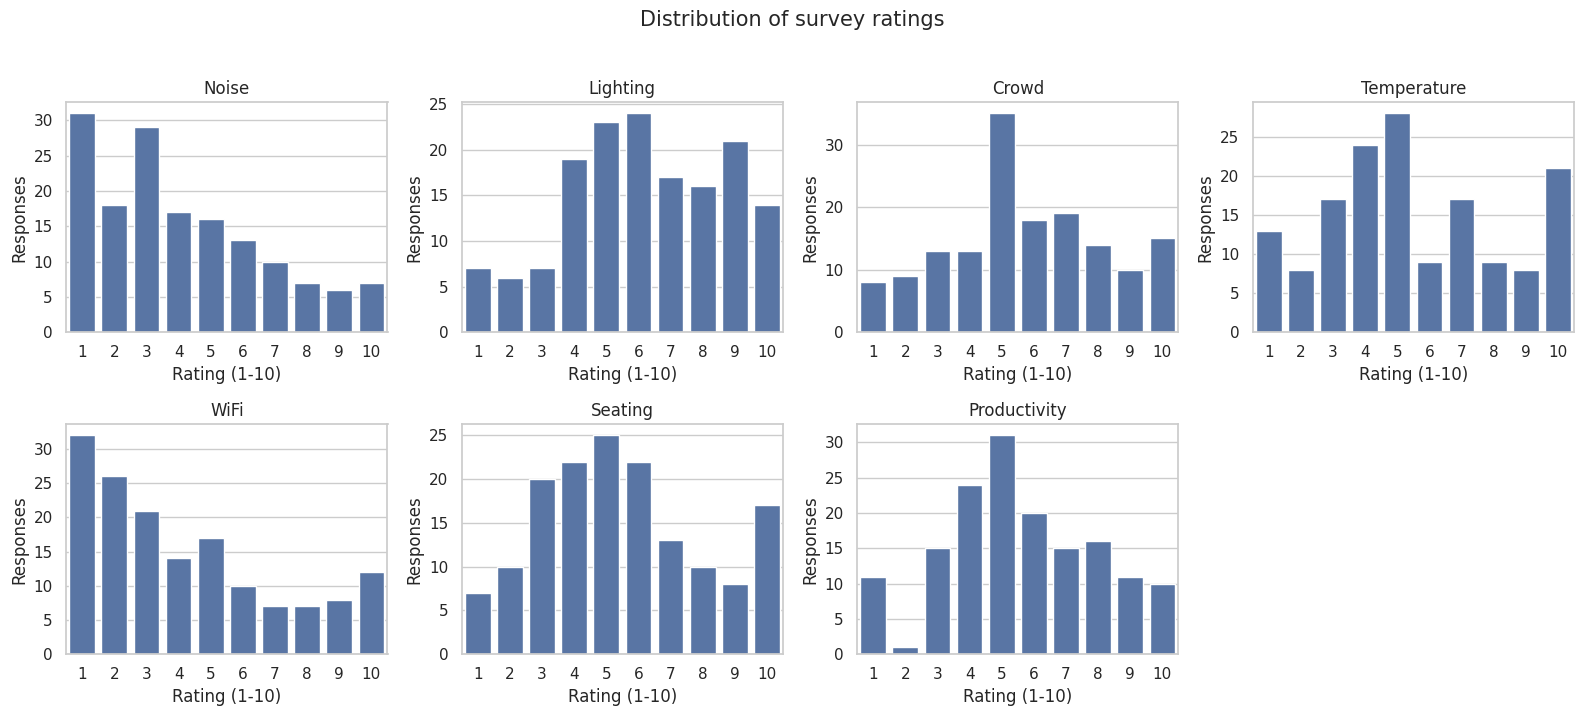

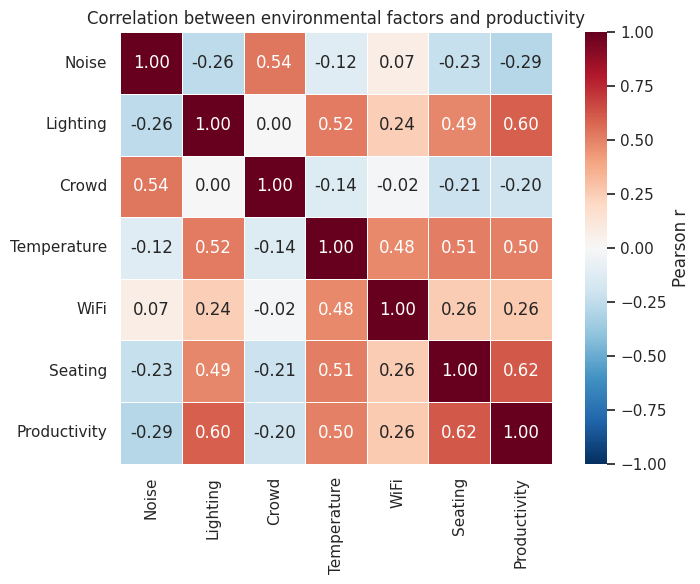


Correlation of each factor with Productivity:
Seating        0.618
Lighting       0.600
Temperature    0.504
WiFi           0.259
Crowd         -0.205
Noise         -0.287


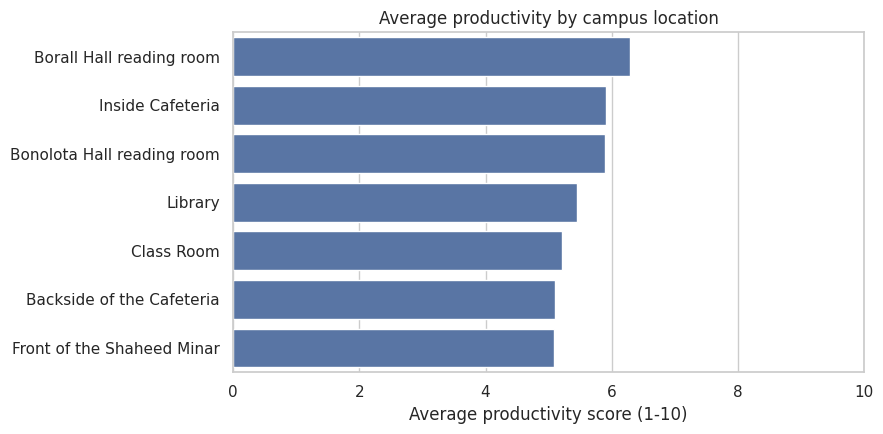

In [18]:
df = raw.copy()
if df.shape[1] == 9:
    df = df.iloc[:, 1:]
df.columns = ["Location"] + FEATURES + [TARGET]

# Cleaning: numeric types, drop missing / out-of-range answers, tidy the text.
for col in FEATURES + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["Location"] = df["Location"].astype(str).str.strip()
before = len(df)
df = df.dropna(subset=FEATURES + [TARGET])
df = df[df[FEATURES + [TARGET]].apply(lambda c: c.between(1, 10)).all(axis=1)]
df = df.reset_index(drop=True)
print(f"Rows removed     : {before - len(df)} (missing or outside the 1-10 scale)")
print(f"Clean shape      : {df.shape[0]} rows")
print(f"Duplicate ratings: {df.duplicated(subset=['Location'] + FEATURES + [TARGET]).sum()}")

print("\nFirst 5 rows:")
print(df.head().to_string())

print("\nSummary statistics (1-10 scale):")
print(df[FEATURES + [TARGET]].describe().round(2).T.to_string())

# Some students ticked several locations in one response. For the per-location
# summary each ticked location gets that rating; for model training we keep one
# row per response so that no rating is counted twice.
loc_df = df.assign(Location=df["Location"].str.split(",")).explode("Location").reset_index(drop=True)
loc_df["Location"] = loc_df["Location"].str.strip()

print("\nAverage rating per campus location (sorted by productivity):")
loc_summary = (loc_df.groupby("Location")[FEATURES + [TARGET]].mean().round(2)
               .assign(Ratings=loc_df.groupby("Location").size())
               .sort_values(TARGET, ascending=False))
print(loc_summary.to_string())

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), FEATURES + [TARGET]):
    sns.countplot(x=df[col].astype(int), ax=ax, color="#4c72b0", order=range(1, 11))
    ax.set_title(col)
    ax.set_xlabel("Rating (1-10)")
    ax.set_ylabel("Responses")
axes.ravel()[-1].axis("off")
fig.suptitle("Distribution of survey ratings", fontsize=15, y=1.02)
save_show("01_feature_distributions.png")

plt.figure(figsize=(8, 6))
corr = df[FEATURES + [TARGET]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson r"})
plt.title("Correlation between environmental factors and productivity")
save_show("02_correlation_heatmap.png")

print("\nCorrelation of each factor with Productivity:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

plt.figure(figsize=(9, 4.5))
sns.barplot(x=loc_summary[TARGET], y=loc_summary.index, color="#4c72b0")
plt.xlabel("Average productivity score (1-10)")
plt.ylabel("")
plt.xlim(0, 10)
plt.title("Average productivity by campus location")
save_show("03_productivity_by_location.png")



STEP 1 - K-MEANS CLUSTERING: Optimal / Moderate / Poor zones
K   Inertia (WCSS)   Silhouette
2          671.89        0.245
3          562.04        0.246
4          493.90        0.195
5          431.54        0.218
6          393.60        0.219
7          363.09        0.244
8          332.61        0.241


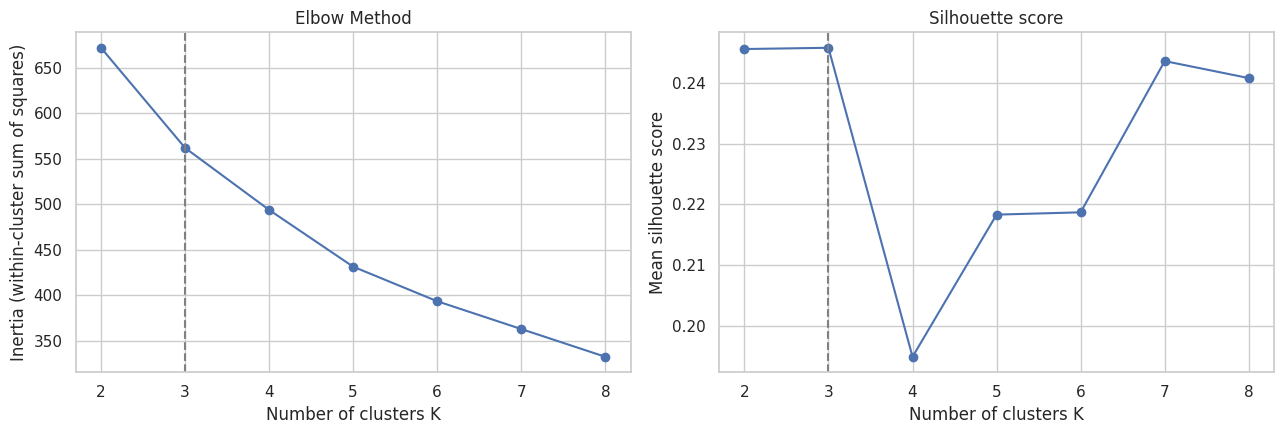


Chosen K = 3   |   silhouette = 0.246

Zone profile (mean rating of each factor):
          Noise  Lighting  Crowd  Temperature  WiFi  Seating  Productivity  Responses
Zone                                                                                 
Optimal    1.93      8.05   4.31         6.91  4.53     7.49          7.24         55
Moderate   6.70      6.93   7.85         7.56  7.59     5.30          5.67         27
Poor       4.76      4.46   6.06         3.60  2.65     4.03          4.31         72


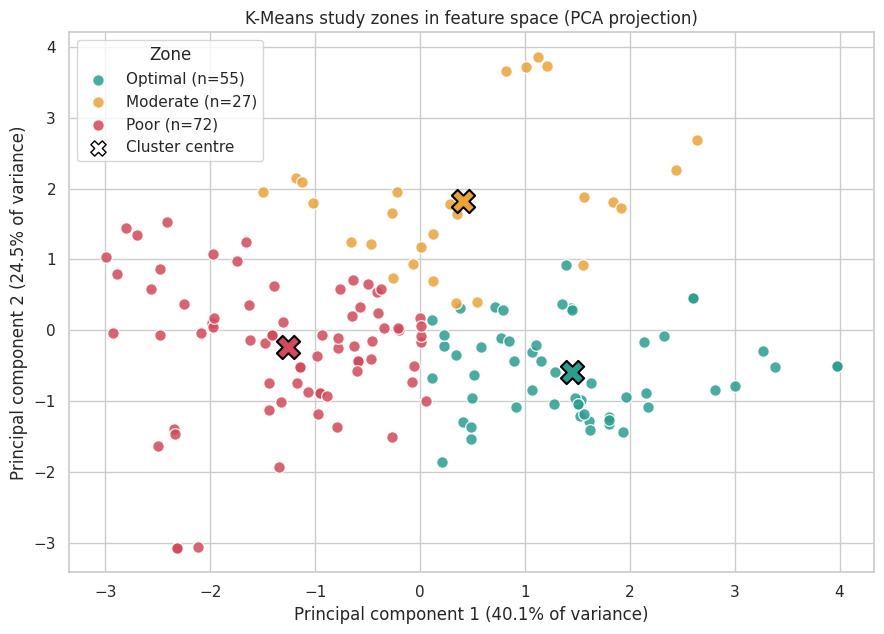

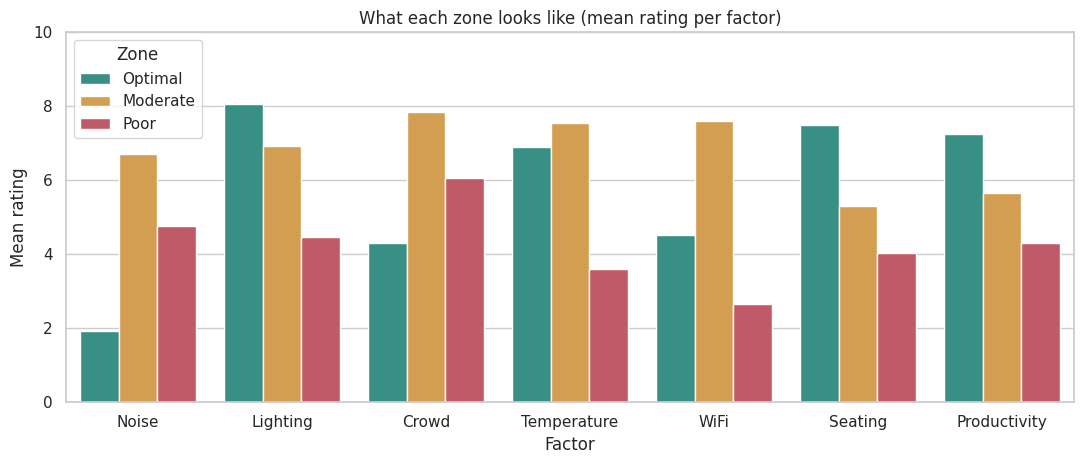


Number of ratings of each location that fell in each zone:
Zone                        Optimal  Moderate  Poor Most common zone
Location                                                            
Backside of the Cafeteria         4         3     3          Optimal
Bonolota Hall reading room        0         0     9             Poor
Borall Hall reading room         18         2    11          Optimal
Class Room                       10         8    24             Poor
Front of the Shaheed Minar        7         1     5          Optimal
Inside Cafeteria                  0         8     3         Moderate
Library                          26        11    37             Poor

Agglomerative (Ward) silhouette      : 0.182
Agreement with K-Means (Adjusted Rand): 0.421   (1 = identical, 0 = random)


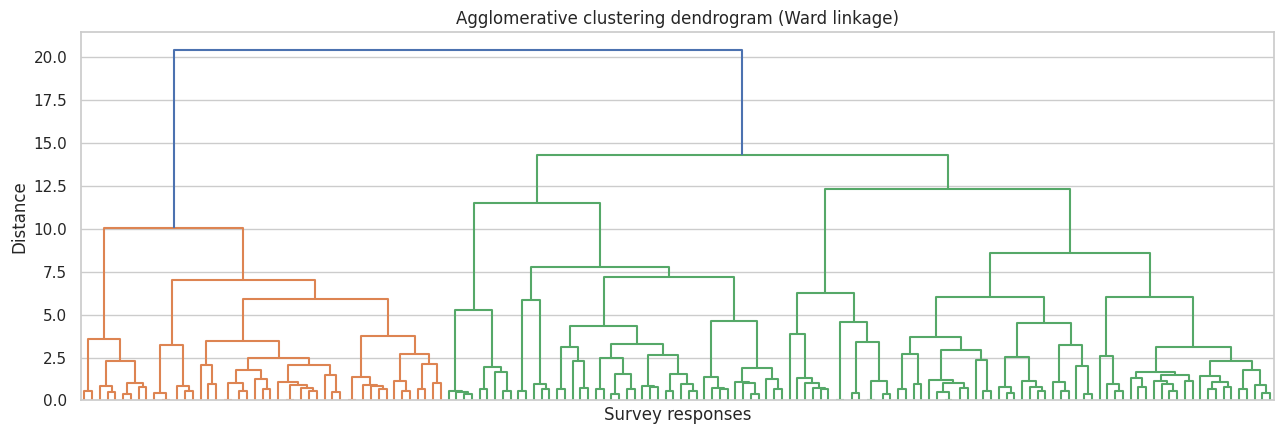

In [19]:
section("STEP 1 - K-MEANS CLUSTERING: Optimal / Moderate / Poor zones")

X = df[FEATURES].values
y_score = df[TARGET].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---- Elbow method + silhouette score ----------------------------------------
k_values = range(2, 9)
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

print("K   Inertia (WCSS)   Silhouette")
for k, i, s in zip(k_values, inertias, silhouettes):
    print(f"{k}   {i:13.2f}   {s:10.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(list(k_values), inertias, marker="o", color="#4c72b0")
ax[0].axvline(3, ls="--", color="grey")
ax[0].set(title="Elbow Method", xlabel="Number of clusters K",
          ylabel="Inertia (within-cluster sum of squares)")
ax[1].plot(list(k_values), silhouettes, marker="o", color="#4c72b0")
ax[1].axvline(3, ls="--", color="grey")
ax[1].set(title="Silhouette score", xlabel="Number of clusters K",
          ylabel="Mean silhouette score")
save_show("04_elbow_method.png")

# ---- Final model: K = 3 (three zones required by the project objective) ------
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# K-Means only gives cluster numbers. We name them by the average productivity
# that students reported in each cluster: highest = Optimal, lowest = Poor.
rank = df.groupby("Cluster")[TARGET].mean().sort_values(ascending=False).index
cluster_to_zone = {cluster: ZONE_ORDER[i] for i, cluster in enumerate(rank)}
df["Zone"] = df["Cluster"].map(cluster_to_zone)

print(f"\nChosen K = {K}   |   silhouette = {silhouette_score(X_scaled, df['Cluster']):.3f}")
print("\nZone profile (mean rating of each factor):")
profile = (df.groupby("Zone")[FEATURES + [TARGET]].mean().round(2)
           .assign(Responses=df["Zone"].value_counts()).reindex(ZONE_ORDER))
print(profile.to_string())

# ---- Cluster scatter plot (PCA to 2-D) --------------------------------------
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)
var = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(9, 6.5))
for zone in ZONE_ORDER:
    m = (df["Zone"] == zone).values
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=70, alpha=0.85, edgecolor="white",
                color=ZONE_COLORS[zone], label=f"{zone} (n={m.sum()})")
for cluster, zone in cluster_to_zone.items():
    plt.scatter(*centers_pca[cluster], marker="X", s=280, color=ZONE_COLORS[zone],
                edgecolor="black", linewidth=1.5)
plt.scatter([], [], marker="X", s=120, color="white", edgecolor="black", label="Cluster centre")
plt.xlabel(f"Principal component 1 ({var[0]:.1f}% of variance)")
plt.ylabel(f"Principal component 2 ({var[1]:.1f}% of variance)")
plt.title("K-Means study zones in feature space (PCA projection)")
plt.legend(title="Zone")
save_show("05_cluster_scatter.png")

# ---- Zone profile bar chart -------------------------------------------------
prof_long = profile[FEATURES + [TARGET]].reset_index().melt(
    id_vars="Zone", var_name="Factor", value_name="Mean rating")
plt.figure(figsize=(11, 4.8))
sns.barplot(data=prof_long, x="Factor", y="Mean rating", hue="Zone",
            hue_order=ZONE_ORDER, palette=ZONE_COLORS)
plt.ylim(0, 10)
plt.title("What each zone looks like (mean rating per factor)")
save_show("06_zone_profiles.png")

# ---- Which zone does each campus location fall in? ---------------------------
loc_zone = df.assign(Location=df["Location"].str.split(",")).explode("Location").reset_index(drop=True)
loc_zone["Location"] = loc_zone["Location"].str.strip()
zone_table = (pd.crosstab(loc_zone["Location"], loc_zone["Zone"])
              .reindex(columns=ZONE_ORDER, fill_value=0))
zone_table["Most common zone"] = zone_table[ZONE_ORDER].idxmax(axis=1)
print("\nNumber of ratings of each location that fell in each zone:")
print(zone_table.to_string())

# ---- Agglomerative clustering as a cross-check ------------------------------
agg = AgglomerativeClustering(n_clusters=K, linkage="ward")
df["AggCluster"] = agg.fit_predict(X_scaled)
print(f"\nAgglomerative (Ward) silhouette      : {silhouette_score(X_scaled, df['AggCluster']):.3f}")
print(f"Agreement with K-Means (Adjusted Rand): {adjusted_rand_score(df['Cluster'], df['AggCluster']):.3f}"
      "   (1 = identical, 0 = random)")

plt.figure(figsize=(13, 4.5))
dendrogram(linkage(X_scaled, method="ward"), no_labels=True, color_threshold=None)
plt.title("Agglomerative clustering dendrogram (Ward linkage)")
plt.xlabel("Survey responses")
plt.ylabel("Distance")
save_show("07_dendrogram.png")



STEP 2 - DECISION TREE: interpretable rules for the zones
Train rows: 115   Test rows: 39

Training accuracy         : 0.930
Test accuracy             : 0.769
5-fold CV accuracy        : 0.818 +/- 0.017

Classification report (test set):
              precision    recall  f1-score   support

     Optimal       0.75      0.86      0.80        14
    Moderate       0.62      0.71      0.67         7
        Poor       0.87      0.72      0.79        18

    accuracy                           0.77        39
   macro avg       0.75      0.76      0.75        39
weighted avg       0.78      0.77      0.77        39

Decision rules (raw 1-10 ratings):
|--- Lighting <= 5.50
|   |--- WiFi <= 7.50
|   |   |--- class: Poor
|   |--- WiFi >  7.50
|   |   |--- Noise <= 4.00
|   |   |   |--- class: Optimal
|   |   |--- Noise >  4.00
|   |   |   |--- class: Moderate
|--- Lighting >  5.50
|   |--- Noise <= 4.50
|   |   |--- Crowd <= 8.50
|   |   |   |--- class: Optimal
|   |   |--- Crowd >  8.50
|   

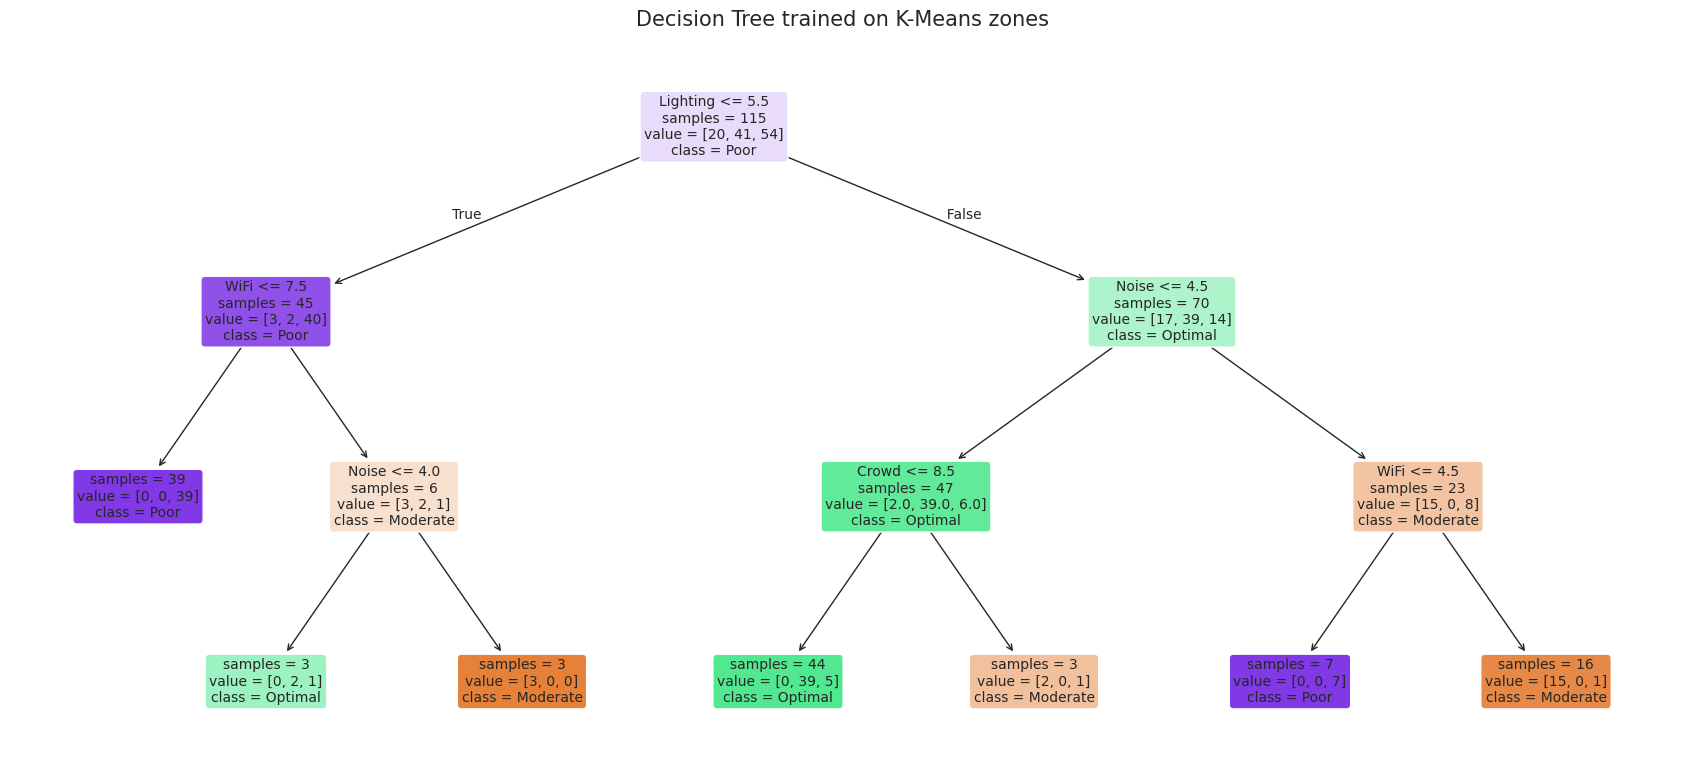


SVM (RBF) test accuracy   : 0.974
SVM (RBF) 5-fold CV       : 0.928 +/- 0.038


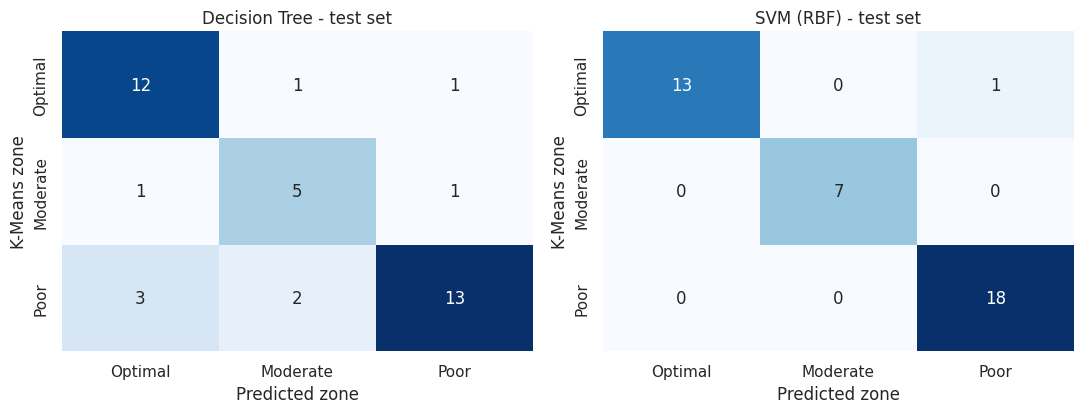

In [20]:
section("STEP 2 - DECISION TREE: interpretable rules for the zones")

y_zone = df["Zone"].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y_zone, test_size=0.25, random_state=RANDOM_STATE, stratify=y_zone)
print(f"Train rows: {len(X_train)}   Test rows: {len(X_test)}")

tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tree_cv = cross_val_score(tree, X, y_zone, cv=cv5)

print(f"\nTraining accuracy         : {tree.score(X_train, y_train):.3f}")
print(f"Test accuracy             : {accuracy_score(y_test, y_pred):.3f}")
print(f"5-fold CV accuracy        : {tree_cv.mean():.3f} +/- {tree_cv.std():.3f}")
print("\nClassification report (test set):")
print(classification_report(y_test, y_pred, labels=ZONE_ORDER, zero_division=0))

print("Decision rules (raw 1-10 ratings):")
print(export_text(tree, feature_names=FEATURES))

print("Feature importance:")
print(pd.Series(tree.feature_importances_, index=FEATURES)
      .sort_values(ascending=False).round(3).to_string())

plt.figure(figsize=(17, 8))
plot_tree(tree, feature_names=FEATURES, class_names=list(tree.classes_), filled=True,
          rounded=True, impurity=False, fontsize=10)
plt.title("Decision Tree trained on K-Means zones", fontsize=15)
save_show("08_decision_tree.png")

# ---- SVM comparison classifier ----------------------------------------------
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale",
                                          random_state=RANDOM_STATE))
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
svm_cv = cross_val_score(svm, X, y_zone, cv=cv5)
print(f"\nSVM (RBF) test accuracy   : {accuracy_score(y_test, svm_pred):.3f}")
print(f"SVM (RBF) 5-fold CV       : {svm_cv.mean():.3f} +/- {svm_cv.std():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for a, pred, name in [(ax[0], y_pred, "Decision Tree"), (ax[1], svm_pred, "SVM (RBF)")]:
    sns.heatmap(confusion_matrix(y_test, pred, labels=ZONE_ORDER), annot=True, fmt="d",
                cmap="Blues", cbar=False, xticklabels=ZONE_ORDER, yticklabels=ZONE_ORDER, ax=a)
    a.set(title=f"{name} - test set", xlabel="Predicted zone", ylabel="K-Means zone")
save_show("09_confusion_matrices.png")


STEP 3 - LINEAR REGRESSION: exact productivity score
Train rows: 115   Test rows: 39

Training R^2              : 0.525
Test R^2                  : 0.414
Test MAE                  : 1.637 points
Test RMSE                 : 2.038 points
Baseline MAE (always mean): 2.270 points
5-fold CV R^2             : 0.465
5-fold CV MAE             : 1.440 points

Intercept: 1.581
Coefficients (change in productivity per +1 rating point):
Temperature    0.261
Seating        0.234
Lighting       0.230
WiFi           0.044
Crowd         -0.013
Noise         -0.065

Equation:
  Productivity = 1.58 - 0.06*Noise + 0.23*Lighting - 0.01*Crowd + 0.26*Temperature + 0.04*WiFi + 0.23*Seating


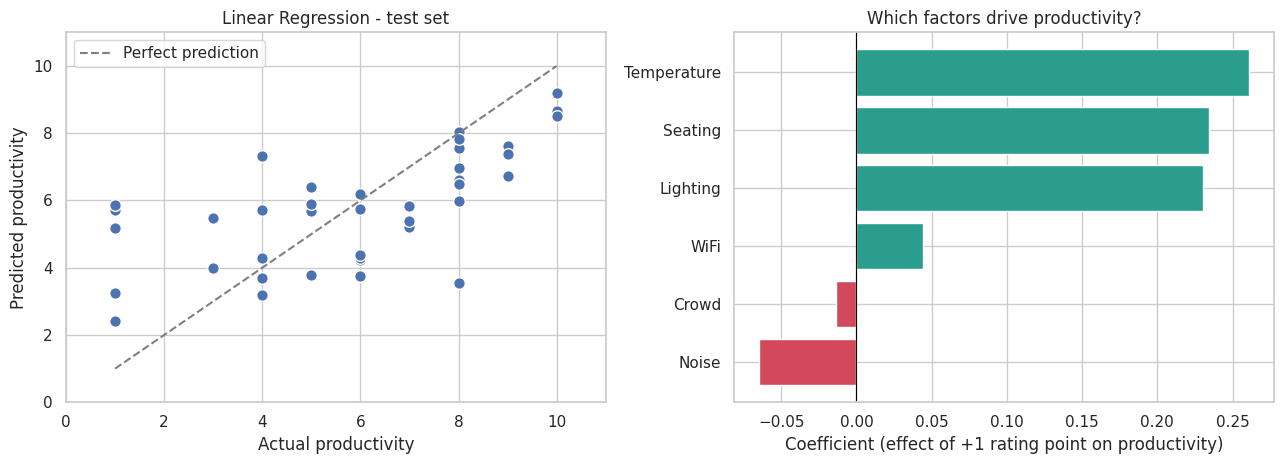

In [21]:

section("STEP 3 - LINEAR REGRESSION: exact productivity score")

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X, y_score, test_size=0.25, random_state=RANDOM_STATE)

linreg = LinearRegression().fit(Xr_train, yr_train)
yr_pred = linreg.predict(Xr_test)

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_pred = cross_val_predict(LinearRegression(), X, y_score, cv=kf)
baseline_mae = mean_absolute_error(yr_test, np.full_like(yr_test, yr_train.mean(), dtype=float))

print(f"Train rows: {len(Xr_train)}   Test rows: {len(Xr_test)}")
print(f"\nTraining R^2              : {linreg.score(Xr_train, yr_train):.3f}")
print(f"Test R^2                  : {r2_score(yr_test, yr_pred):.3f}")
print(f"Test MAE                  : {mean_absolute_error(yr_test, yr_pred):.3f} points")
print(f"Test RMSE                 : {np.sqrt(mean_squared_error(yr_test, yr_pred)):.3f} points")
print(f"Baseline MAE (always mean): {baseline_mae:.3f} points")
print(f"5-fold CV R^2             : {r2_score(y_score, cv_pred):.3f}")
print(f"5-fold CV MAE             : {mean_absolute_error(y_score, cv_pred):.3f} points")

coef = pd.Series(linreg.coef_, index=FEATURES).sort_values()
print(f"\nIntercept: {linreg.intercept_:.3f}")
print("Coefficients (change in productivity per +1 rating point):")
print(coef.sort_values(ascending=False).round(3).to_string())
print("\nEquation:")
print("  Productivity = " + f"{linreg.intercept_:.2f} "
      + " ".join(f"{'+' if c >= 0 else '-'} {abs(c):.2f}*{f}" for f, c in zip(FEATURES, linreg.coef_)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(yr_test, yr_pred, s=70, color="#4c72b0", edgecolor="white")
ax[0].plot([1, 10], [1, 10], ls="--", color="grey", label="Perfect prediction")
ax[0].set(xlim=(0, 11), ylim=(0, 11), xlabel="Actual productivity",
          ylabel="Predicted productivity", title="Linear Regression - test set")
ax[0].legend()
ax[1].barh(coef.index, coef.values, color=["#d1495b" if v < 0 else "#2a9d8f" for v in coef.values])
ax[1].axvline(0, color="black", lw=0.8)
ax[1].set(xlabel="Coefficient (effect of +1 rating point on productivity)",
          title="Which factors drive productivity?")
save_show("10_linear_regression.png")


STEP 4 - MODEL ACCURACY SUMMARY
Zone classification (predicting Optimal / Moderate / Poor):
              Train accuracy Test accuracy 5-fold CV accuracy CV std Precision (macro) Recall (macro) F1-score (macro)
Model                                                                                                                 
Decision Tree         93.0 %        76.9 %             81.8 %  1.7 %            74.7 %         76.5 %           75.2 %
SVM (RBF)             98.3 %        97.4 %             92.8 %  3.8 %            98.2 %         97.6 %           97.9 %

Productivity score prediction (Linear Regression):
                         Train    Test  5-fold CV
R^2 score                0.525   0.414      0.465
MAE (points)             1.276   1.637      1.440
RMSE (points)            1.554   2.038      1.734
Within +/-1 point (%)   46.087  28.205     35.714
Within +/-2 points (%)  78.261  74.359     75.325

Clustering quality (silhouette: -1 = bad, 0 = overlapping, 1 = perfect):
  K-M

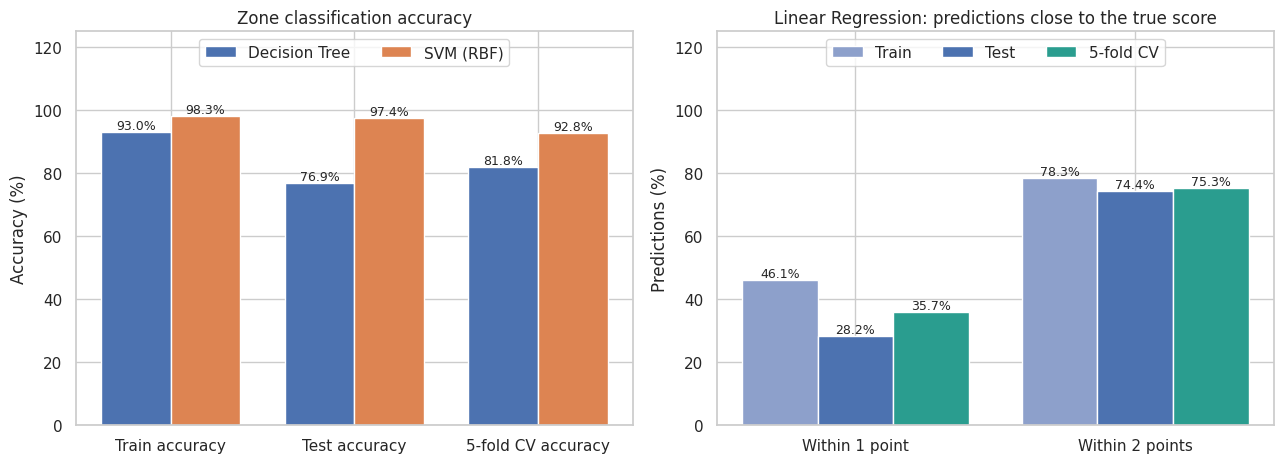

In [22]:

section("STEP 4 - MODEL ACCURACY SUMMARY")

from sklearn.metrics import f1_score, precision_score, recall_score

clf_rows = []
for name, model, pred, cv_scores in [("Decision Tree", tree, y_pred, tree_cv),
                                     ("SVM (RBF)", svm, svm_pred, svm_cv)]:
    clf_rows.append({
        "Model": name,
        "Train accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Test accuracy": accuracy_score(y_test, pred),
        "5-fold CV accuracy": cv_scores.mean(),
        "CV std": cv_scores.std(),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
    })
clf_table = pd.DataFrame(clf_rows).set_index("Model")
print("Zone classification (predicting Optimal / Moderate / Poor):")
print((clf_table * 100).round(1).astype(str).add(" %").to_string())


def within(true, pred, tol):
    return np.mean(np.abs(np.asarray(true) - np.asarray(pred)) <= tol)

reg_table = pd.DataFrame({
    "Train": [r2_score(yr_train, linreg.predict(Xr_train)),
              mean_absolute_error(yr_train, linreg.predict(Xr_train)),
              np.sqrt(mean_squared_error(yr_train, linreg.predict(Xr_train))),
              within(yr_train, linreg.predict(Xr_train), 1) * 100,
              within(yr_train, linreg.predict(Xr_train), 2) * 100],
    "Test": [r2_score(yr_test, yr_pred),
             mean_absolute_error(yr_test, yr_pred),
             np.sqrt(mean_squared_error(yr_test, yr_pred)),
             within(yr_test, yr_pred, 1) * 100,
             within(yr_test, yr_pred, 2) * 100],
    "5-fold CV": [r2_score(y_score, cv_pred),
                  mean_absolute_error(y_score, cv_pred),
                  np.sqrt(mean_squared_error(y_score, cv_pred)),
                  within(y_score, cv_pred, 1) * 100,
                  within(y_score, cv_pred, 2) * 100],
}, index=["R^2 score", "MAE (points)", "RMSE (points)",
          "Within +/-1 point (%)", "Within +/-2 points (%)"])
print("\nProductivity score prediction (Linear Regression):")
print(reg_table.round(3).to_string())

# ---- Clustering quality -------------------------------------------------------
print("\nClustering quality (silhouette: -1 = bad, 0 = overlapping, 1 = perfect):")
print(f"  K-Means (K=3)        : {silhouette_score(X_scaled, df['Cluster']):.3f}")
print(f"  Agglomerative (Ward) : {silhouette_score(X_scaled, df['AggCluster']):.3f}")

# ---- Accuracy chart -----------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
metrics = ["Train accuracy", "Test accuracy", "5-fold CV accuracy"]
x = np.arange(len(metrics))
for i, (name, color) in enumerate([("Decision Tree", "#4c72b0"), ("SVM (RBF)", "#dd8452")]):
    vals = clf_table.loc[name, metrics].values * 100
    bars = ax[0].bar(x + (i - 0.5) * 0.38, vals, width=0.38, color=color, label=name)
    ax[0].bar_label(bars, fmt="%.1f%%", fontsize=9)
ax[0].set(xticks=x, xticklabels=metrics, ylim=(0, 125), ylabel="Accuracy (%)",
          title="Zone classification accuracy")
ax[0].legend(loc="upper center", ncol=2)

reg_metrics = ["Within +/-1 point (%)", "Within +/-2 points (%)"]
x2 = np.arange(len(reg_metrics))
for i, (col, color) in enumerate([("Train", "#8da0cb"), ("Test", "#4c72b0"), ("5-fold CV", "#2a9d8f")]):
    bars = ax[1].bar(x2 + (i - 1) * 0.27, reg_table.loc[reg_metrics, col].values,
                     width=0.27, color=color, label=col)
    ax[1].bar_label(bars, fmt="%.1f%%", fontsize=9)
ax[1].set(xticks=x2, xticklabels=["Within 1 point", "Within 2 points"], ylim=(0, 125),
          ylabel="Predictions (%)", title="Linear Regression: predictions close to the true score")
ax[1].legend(loc="upper center", ncol=3)
save_show("11_model_accuracy.png")

In [23]:
section("STEP 5 - PREDICTOR: 6 inputs -> zone + productivity score")

# Refit the final models on ALL the data so the predictor uses every response.
final_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3,
                                    random_state=RANDOM_STATE).fit(X, y_zone)
final_reg = LinearRegression().fit(X, y_score)


def predict_spot(noise, lighting, crowd, temperature, wifi, seating):
    """Return (zone, productivity score) for one set of 1-10 ratings."""
    row = np.array([[noise, lighting, crowd, temperature, wifi, seating]], dtype=float)
    zone = final_tree.predict(row)[0]
    score = float(np.clip(final_reg.predict(row)[0], 1, 10))
    return zone, round(score, 2)


examples = {
    "Quiet, bright, comfortable room": (2, 9, 3, 8, 8, 9),
    "Average classroom":               (5, 6, 5, 5, 4, 5),
    "Noisy, crowded cafeteria":        (9, 4, 9, 4, 3, 3),
}
print("Example predictions")
print(f"{'Scenario':34s} {'N  L  C  T  W  S':18s} {'Zone':10s} Score")
for name, vals in examples.items():
    zone, score = predict_spot(*vals)
    print(f"{name:34s} {'  '.join(str(v) for v in vals):18s} {zone:10s} {score}")

# Save the labelled dataset so it can go in the report appendix.
df.drop(columns=["Cluster", "AggCluster"]).to_csv(
    os.path.join(OUT_DIR, "study_spots_with_zones_predictions.csv"), index=False)


def ask(prompt):
    while True:
        value = float(input(f"  {prompt} (1-10): "))
        if 1 <= value <= 10:
            return value
        print("    Please enter a number between 1 and 10.")


print("\n--- Try your own study spot (type the 6 ratings) ---")
try:
    while True:
        vals = [ask(q) for q in ["Noise level", "Lighting quality", "Crowd density",
                                 "Temperature comfort", "WiFi speed", "Seating comfort"]]
        zone, score = predict_spot(*vals)
        print(f"\n  >> Predicted zone        : {zone}")
        print(f"  >> Predicted productivity: {score} / 10\n")
        if input("Predict another spot? (y/n): ").strip().lower() != "y":
            break
except (EOFError, KeyboardInterrupt, ValueError):
    print("(interactive input skipped)")

print("\nDone. All figures are saved in the 'outputs' folder.")


STEP 5 - PREDICTOR: 6 inputs -> zone + productivity score
Example predictions
Scenario                           N  L  C  T  W  S   Zone       Score
Quiet, bright, comfortable room    2  9  3  8  8  9   Optimal    8.38
Average classroom                  5  6  5  5  4  5   Poor       5.33
Noisy, crowded cafeteria           9  4  9  4  3  3   Poor       3.33

--- Try your own study spot (type the 6 ratings) ---
  Noise level (1-10): 8
  Lighting quality (1-10): 8
  Crowd density (1-10): 8
  Temperature comfort (1-10): 8
  WiFi speed (1-10): 8
  Seating comfort (1-10): 8

  >> Predicted zone        : Moderate
  >> Predicted productivity: 6.99 / 10

Predict another spot? (y/n): n

Done. All figures are saved in the 'outputs' folder.
